In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GCNConv
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import tqdm as notebook_tqdm

In [4]:
GRAPH_PATH = "../data/processed/graph_data.pt"

graph_data = torch.load(
    GRAPH_PATH,
    weights_only=False
)

device = torch.device("cpu")
graph_data = graph_data.to(device)

print(graph_data)

Data(x=[4404, 136], edge_index=[2, 50000], y=[4404], train_mask=[4404], val_mask=[4404], test_mask=[4404])


In [5]:
class GCNModel(nn.Module):

    def __init__(self, input_features, hidden_features, output_classes):
        super().__init__()

        self.conv1 = GCNConv(
            input_features,
            hidden_features
        )

        self.conv2 = GCNConv(
            hidden_features,
            hidden_features
        )

        self.classifier = nn.Linear(
            hidden_features,
            output_classes
        )

    def forward(self, x, edge_index):

        x = self.conv1(x, edge_index)
        x = F.relu(x)

        x = F.dropout(
            x,
            p=0.5,
            training=self.training
        )

        x = self.conv2(x, edge_index)
        x = F.relu(x)

        x = self.classifier(x)

        return x

In [6]:
model = GCNModel(
    input_features=graph_data.num_node_features,
    hidden_features=32,
    output_classes=2
).to(device)

print(model)

GCNModel(
  (conv1): GCNConv(136, 32)
  (conv2): GCNConv(32, 32)
  (classifier): Linear(in_features=32, out_features=2, bias=True)
)


In [7]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=5e-4
)

In [8]:
EPOCHS = 100

train_losses = []
val_accuracies = []

for epoch in range(1, EPOCHS + 1):

    model.train()

    optimizer.zero_grad()

    output = model(
        graph_data.x,
        graph_data.edge_index
    )

    loss = criterion(
        output[graph_data.train_mask],
        graph_data.y[graph_data.train_mask]
    )

    loss.backward()
    optimizer.step()

    model.eval()

    with torch.no_grad():

        validation_output = model(
            graph_data.x,
            graph_data.edge_index
        )

        validation_predictions = validation_output.argmax(dim=1)

        validation_accuracy = accuracy_score(
            graph_data.y[graph_data.val_mask].cpu().numpy(),
            validation_predictions[graph_data.val_mask].cpu().numpy()
        )

    train_losses.append(loss.item())
    val_accuracies.append(validation_accuracy)

    if epoch == 1 or epoch % 10 == 0:

        print(
            f"Epoch {epoch:03d} | "
            f"Loss: {loss.item():.4f} | "
            f"Validation Accuracy: {validation_accuracy:.4f}"
        )

Epoch 001 | Loss: 0.5953 | Validation Accuracy: 0.9970
Epoch 010 | Loss: 0.0098 | Validation Accuracy: 0.9985
Epoch 020 | Loss: 0.0040 | Validation Accuracy: 0.9985
Epoch 030 | Loss: 0.0037 | Validation Accuracy: 0.9985
Epoch 040 | Loss: 0.0045 | Validation Accuracy: 0.9985
Epoch 050 | Loss: 0.0026 | Validation Accuracy: 0.9985
Epoch 060 | Loss: 0.0031 | Validation Accuracy: 0.9985
Epoch 070 | Loss: 0.0033 | Validation Accuracy: 0.9985
Epoch 080 | Loss: 0.0017 | Validation Accuracy: 0.9985
Epoch 090 | Loss: 0.0023 | Validation Accuracy: 0.9985
Epoch 100 | Loss: 0.0011 | Validation Accuracy: 0.9985


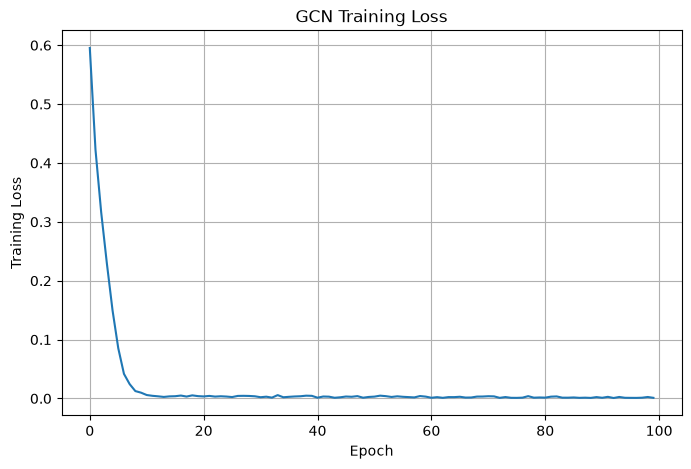

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(train_losses)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("GCN Training Loss")

plt.grid()
plt.show()

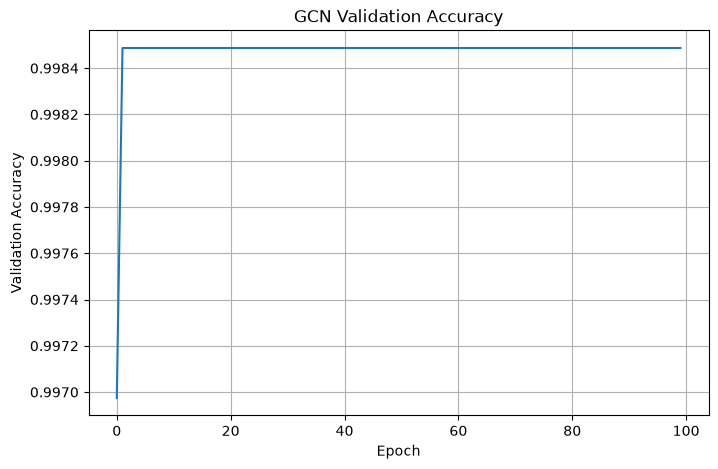

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(val_accuracies)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("GCN Validation Accuracy")

plt.grid()
plt.show()

In [11]:
model.eval()

with torch.no_grad():

    test_output = model(
        graph_data.x,
        graph_data.edge_index
    )

    test_predictions = test_output.argmax(dim=1)

test_true = graph_data.y[graph_data.test_mask].cpu().numpy()
test_pred = test_predictions[graph_data.test_mask].cpu().numpy()

test_accuracy = accuracy_score(
    test_true,
    test_pred
)

print("Test Accuracy:", test_accuracy)

Test Accuracy: 1.0


In [12]:
print(
    classification_report(
        test_true,
        test_pred,
        labels=[0, 1],
        target_names=["Normal", "Attack"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       661
      Attack       0.00      0.00      0.00         0

    accuracy                           1.00       661
   macro avg       0.50      0.50      0.50       661
weighted avg       1.00      1.00      1.00       661



In [13]:
cm = confusion_matrix(
    test_true,
    test_pred,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[661   0]
 [  0   0]]


In [14]:
MODEL_PATH = "../outputs/gcn_model.pt"

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_features": graph_data.num_node_features,
        "hidden_features": 32,
        "output_classes": 2
    },
    MODEL_PATH
)

print("Trained model saved successfully.")

Trained model saved successfully.


In [15]:
print("DAY 7 COMPLETED SUCCESSFULLY")
print("GCN model trained and evaluated.")

DAY 7 COMPLETED SUCCESSFULLY
GCN model trained and evaluated.


In [16]:
print("All labels:")
print(torch.bincount(graph_data.y, minlength=2))

print("\nTraining labels:")
print(torch.bincount(graph_data.y[graph_data.train_mask], minlength=2))

print("\nValidation labels:")
print(torch.bincount(graph_data.y[graph_data.val_mask], minlength=2))

print("\nTesting labels:")
print(torch.bincount(graph_data.y[graph_data.test_mask], minlength=2))

All labels:
tensor([4402,    2])

Training labels:
tensor([3081,    1])

Validation labels:
tensor([660,   1])

Testing labels:
tensor([661,   0])
